In [10]:
import matplotlib.pyplot as plt
import pandas as pd
import os

In [ ]:
input_path = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/dataSet/data-preProcessed/feature_engineering/espectros_derivadasLocais_bandasSelecionadas.csv"
output_dir = "/mnt/c/Users/jefferson.faria/Documents/GitHub/ic-2025/ETL/data_features"
output_path = os.path.join(output_dir, "data_indices_espectrais.csv")

In [12]:
df = pd.read_csv(input_path)
i = pd.DataFrame(index=df.index)

In [13]:
if df.shape[1] >= 2:
    i["indice1"] = (df.iloc[:, 1] - df.iloc[:, 0]) / (df.iloc[:, 1] + df.iloc[:, 0] + 1e-9)
    i["indice2"] = df.iloc[:, 1] / (df.iloc[:, 0] + 1e-9)

if df.shape[1] >= 3:
    i["indice3"] = df.iloc[:, 2] - df.iloc[:, 0]

In [14]:
data_features_final = pd.concat([df, i], axis=1)

print(data_features_final.head())

   deriv_desvio_padrao  deriv_curtose  deriv_skewness  razao_col0_col1  \
0             1.435968       7.247350      -11.473377        -0.306472   
1             1.438195       7.245376      -11.475780        -0.303946   
2             0.026035       2.632927       -4.461090        -0.038664   
3             0.025006       3.571883       -5.480607        -0.202468   
4             0.033897       5.314908       -7.835862        -0.072247   

   razao_col1_col2   indice1     indice2    indice3  
0         0.131687  0.669258    5.047013 -12.909345  
1         0.132117  0.668755    5.037827 -12.913974  
2         0.009430  0.980417  101.128995  -4.487125  
3         0.005788  0.986095  142.838312  -5.505614  
4         0.005913  0.987325  156.796058  -7.869759  


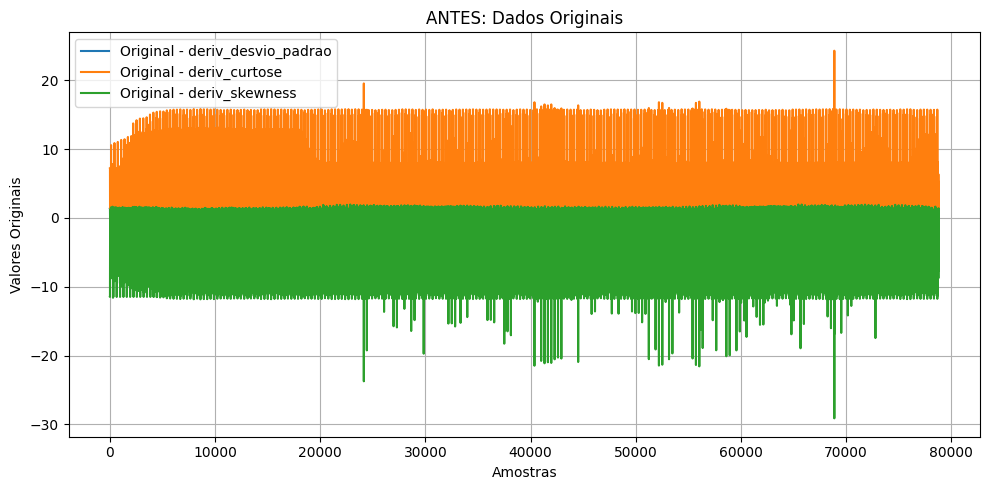

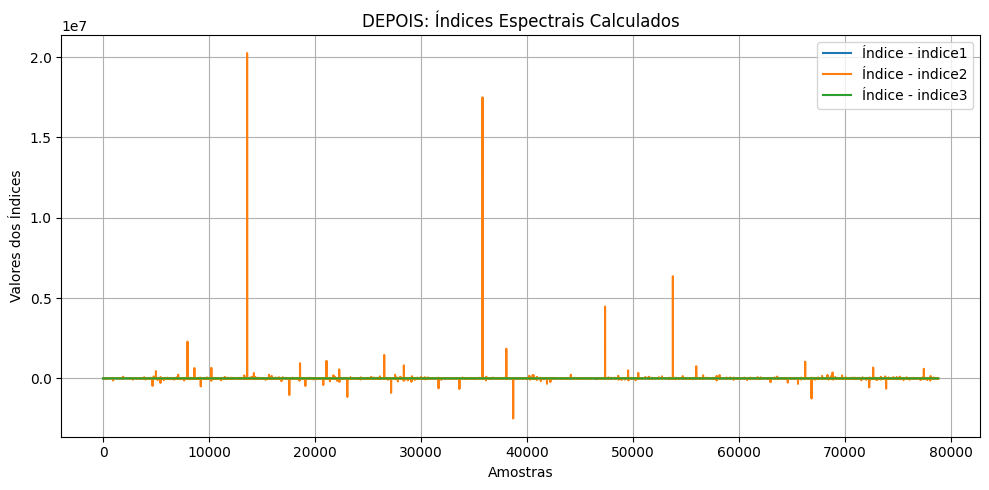

In [ ]:
# Antes: apenas os dados originais
plt.figure(figsize=(10, 5))
for col in df.columns[:min(3, df.shape[1])]:  # plota até 3 colunas para não poluir
    plt.plot(df.index, df[col], label=f"Original - {col}")
plt.title("ANTES: Dados Originais")
plt.xlabel("Amostras")
plt.ylabel("Valores Originais")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# Depois: apenas os índices espectrais
plt.figure(figsize=(10, 5))
for col in i.columns:
    plt.plot(i.index, i[col], label=f"Índice - {col}")
plt.title("DEPOIS: Índices Espectrais Calculados")
plt.xlabel("Amostras")
plt.ylabel("Valores dos Índices")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

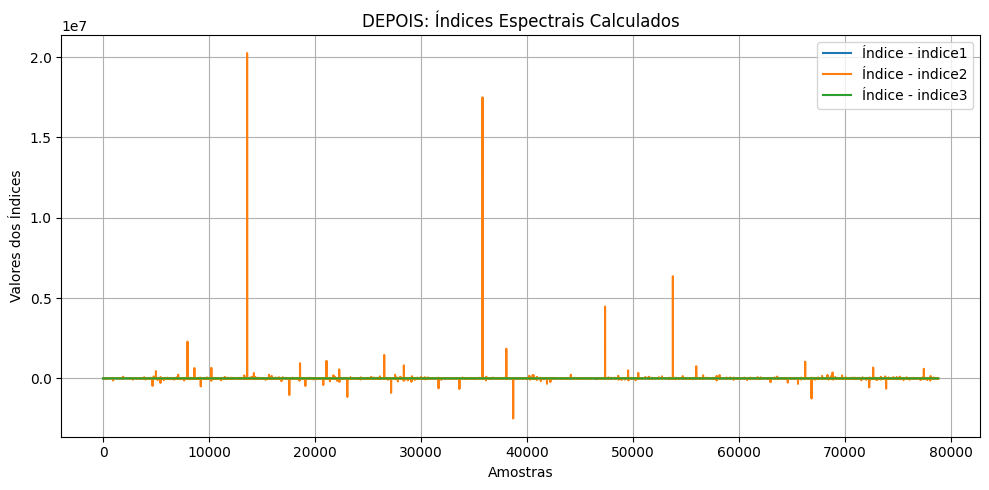

In [16]:
plt.figure(figsize=(10, 5))
for col in i.columns:
    plt.plot(i.index, i[col], label=f"Índice - {col}")
plt.title("DEPOIS: Índices Espectrais Calculados")
plt.xlabel("Amostras")
plt.ylabel("Valores dos Índices")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()